# NB Pipeline explanatory notebooks
## Notebook 2: Negative Binomial Model

The statistical model chosen to model clonotype counts is the Negative Binomial Distribution. In this notebook we will justify the choice of this distribution as well as the corrections made to it using biological considerations that arose in the EDA phase of section 1. We validate the model using simulations.

The objectgive of the pipeline is to determine which patient clonotypes are non-neutral. This is done by testing them agains a **null model** or **null hypothesis**, which we establish using **healthy donors**. In the literature, the most common way to establish a **null model** is using technical replicates from which the sampling noise can be determined, allowing to distinghish what is biological non-neutrality. Why use donors instead of replicates?
* `Resource/Funding contrains`: Technical replicates are expensive and not always a viable option due to resource limiation, as is our case. This would put our pipeline is a graceful spot with respect to other T-cell dynamics methdologies. All RNA-seq based methods rely on technical replicates for noise estiamtion, and even though some of them give the option to perfor analysis without them, they do specificallyt adress the propblems that arise from not using them. Our pipeline does adress them.
* `Bilological considerations`: There is also a biological argument to not use technical replicates (**REFERENCE**), or rather, to use healthy donors. Tehcnical replicates come from the patients own samples, which are expected to have more uderlying non-neutrality than a healthy person. During the computation of the sample noise, part of the genuine biology happening in the clonotype trajectotries can get confounded with technical noise, obscuring the detection of neutral clonotypes. By using healthy donors as the null baseline, we are asking a fundamentally different question for the null: How do healthy T-cell dynamics look like? 

In [9]:
import sys
sys.path.insert(0, '..')

import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

from tcr_pipeline.normalization import tmm_normalize
from tcr_pipeline.data_io import list_subjects, load_group, load_subject, sample_qc, drop_failed_samples
from tcr_pipeline import nb_glm as nb

warnings.filterwarnings('ignore')
pd.set_option('display.width', 160)

DONOR_COLORS = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300']
GREY, INK = '#8a8984', '#3d3c39'
plt.rcParams.update({
    'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.color': '#e6e5e0', 'grid.linewidth': 0.6,
    'axes.edgecolor': GREY, 'axes.labelcolor': INK, 'xtick.color': '#52514e',
    'ytick.color': '#52514e', 'lines.linewidth': 1.6, 'lines.markersize': 5,
    'legend.frameon': False, 'font.size': 9.5, 'axes.titlesize': 10})


#### Warning: With the attached TMM factor, the data frames can be expensive in memory

In [ ]:
healthy_raw = load_group('donors', with_D_t=True, with_freq=True)
d_qc = nb.attach_offset(tmm_normalize(drop_failed_samples(healthy_raw, sample_qc(healthy_raw))))

DONORS = sorted(d_qc['patient'].unique())
COLOR = dict(zip(DONORS, DONOR_COLORS))
short = lambda p: p.replace('_SEQTR', '').replace('_ReSeq', '')
print(len(d_qc), 'rows,', d_qc.groupby(['patient', 'day']).ngroups, 'samples,',
      len(DONORS), 'donors')

## 2.1 The model

For clone $c$ in sample $t$ of one person, the read count is

$$x_{ct} \sim \mathrm{NB}\!\left(\mu_{ct},\ \phi\right), \qquad
\log\mu_{ct} = \log L_t\ + \log\lambda_c + \beta_c s_t, \qquad s_t = \frac{t-\bar{t}}{t_{last} - t_{first}},\qquad
\mathrm{Var}(x_{ct}) = \mu_{ct} + \frac{\mu_{ct}^2}{\phi}.$$

* $\lambda_c$ is the clone's frequency. Under the **null** it is the same in every
  sample: the clone neither expands nor contracts.
* $L_t = D_t \times \text{TMM}_t$ is the sample's **offset**: its in-frame depth $D_t$
  (Section 1.1) times a TMM normalisation factor computed within the person, so that
  $\mu_{ct}$ is the expected count of a clone of frequency $\lambda_c$ in that sample. We use TMM as a robust normalization factor to correct for different sequencing depth across samples, but other normalization factor can be used.
* $\phi$ is the **dispersion**. The NB is a Poisson whose mean is itself multiplied by
  a random factor with mean 1 and squared coefficient of variation $1/\phi$. This dispersion (sometimes called overdispersion) encapsulates
  sample-to-sample noise of library preparation, RNA content per cell, amplification.
  Small $\phi$ means noisy, $\phi \to \infty$ is a Poisson (only pure sampling noise).
* $\beta_c$: the clone’s trajectory. $s_t$ is time rescaled to run over one unit across the series, so $\beta_c$ is the log fold change from the first sample to the last. For example,   $\beta_c = \log 10$ is a 10-fold expansion over the series and $\beta_c = -\log 10$ a 10-fold contraction

This is a GLM per clone: a log link, an offset, two coefficients ($\alpha_c$, $\beta_c$) and a dispersion fixed in advance.

**The null hypothesis** $H_0: \beta_c = 0$, but the meaning of “neutral” is set by the donors. Their $\phi$ is estimated with $\beta_c = 0$ for every clone, so any fluctuation healthy clones show, technical or biological, is absorbed into $\phi$. A patient clone is therefore called non-neutral when it changes more than clones in healthy people do, not merely when it is not constant. The healthy donors are assumed neutral, so $\phi$ is estimated under the null model, $\log\mu_{ct} = \log L_t + \alpha_c$, with only $\alpha_c$ fitted per clone. If a donor clone does change, the null model reads its change as extra noise and lowers $\phi$, the conservative direction. The full model with $\beta_c$ is only fitted when patients are tested.

In [ ]:
#From now on we use the QC filtered data, dropping HDBR06 day 21
offsets = (d_qc.groupby(['patient', 'day'], observed=True)[['D_t', 'tmm_factor', 'lib']].first()
             .rename(columns={'lib': 'L_t'}))
offsets.index = offsets.index.set_levels(offsets.index.levels[0].map(short), level=0)
display(offsets.round({'D_t': 0, 'tmm_factor': 3, 'L_t': 0}))

D_t  tmm_factor         L_t
patient day                                  
HD106   0    21258772       0.819  17412074.0
        46   20765301       0.988  20517047.0
        82   13524147       1.082  14626523.0
        131  17575872       1.000  17575872.0
HD197   0    16537619       1.000  16537619.0
        46   15524871       1.072  16644402.0
        82   18141316       1.072  19442764.0
        131  18289621       1.083  19809672.0
HDBR01  0    10380249       1.167  12111934.0
        21   13135420       0.931  12227167.0
        42   21684876       0.747  16189793.0
        126  14117466       1.000  14117466.0
HDBR02  0     5522816       1.223   6756502.0
        48    8975122       0.895   8028455.0
        71    6840967       1.000   6840967.0
HDBR03  0    10820547       0.721   7796750.0
        21    5093101       1.080   5501255.0
        35    6584605       1.000   6584605.0
        66    5205213       1.078   5609171.0
        84    5610753       1.172   6573196.0
HDBR06  0    10824659       0.871   9424946.0
        82   11651005       0.817   9518842.0
        105  11058680       1.000  11058680.0

## 2.2 Why NB instead of Poisson?
The reason of using NB over a simpler Poisson model is the count noise is not only due to pure samplign noise, but there are other external factors that need to be taken into consideration through the dispersion $\phi$. Next, we will investigate and justify this claim using the donor data itself.

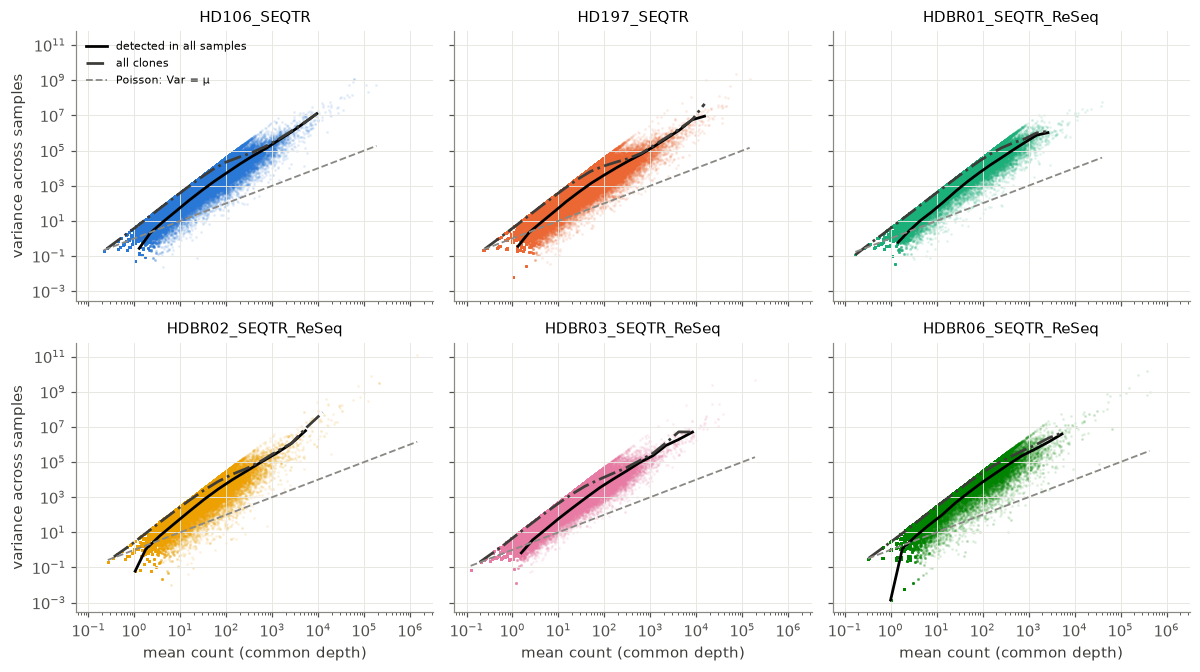

In [ ]:
def mean_variance(g, mode='all', c=1, depth_col='D_t'):
    days = np.sort(g['day'].unique())
    L = g.groupby('day')[depth_col].first().reindex(days).to_numpy()
    X = (g.pivot_table(index='clono', columns='day', values='count', aggfunc='sum',
                       fill_value=0, observed=True)
           .reindex(columns=days, fill_value=0).to_numpy(float))
    det = X >= c
    if mode == 'all':
        keep = det.all(axis=1)             # detected in every sample
    elif mode == 'any':
        keep = np.ones(len(X), dtype=bool) # every clone in the table
    else:
        raise ValueError(mode)
    Y = X[keep] * (L.mean() / L)           # zeros stay zeros; they are real observations at c = 1
    return Y.mean(axis=1), Y.var(axis=1, ddof=1)

def binned(m, v, edges, min_n=20):
    k = np.digitize(m, edges)
    grp = [i for i in np.unique(k) if (k == i).sum() >= min_n]
    return (np.array([m[k == i].mean() for i in grp]),
            np.array([v[k == i].mean() for i in grp]))

ORANGE = '#d9822b'
rng = np.random.default_rng(0)

fig, axes = plt.subplots(2, 3, figsize=(11, 6.2), sharex=True, sharey=True)
for ax, p in zip(axes.ravel(), DONORS):
    g = d_qc[d_qc['patient'] == p]
    res = {mode: mean_variance(g, mode) for mode in ['all', 'any']}
    m_any = res['any'][0]
    edges = np.logspace(np.log10(m_any.min()), np.log10(m_any.max()), 22)
    m, v = res['any']
    idx = rng.choice(len(m), size=min(len(m), 100_000), replace=False)
    ax.scatter(m[idx], v[idx], s=1, color=COLOR[p], alpha=0.06, rasterized=True) 
    idx = rng.choice(len(m), size=min(len(m), 100_000), replace=False)
    ax.scatter(m[idx], v[idx], s=1, color=COLOR[p], alpha=0.06, rasterized=True)
    
    ax.scatter(m, v, s=1, color=COLOR[p], alpha=0.08, rasterized=True)

    for mode, col, lab, linest in [('all', "black", 'detected in all samples', "solid"),
                           ('any', INK, 'all clones', "dashdot")]:
        mb, vb = binned(*res[mode], edges)
        ax.plot(mb, vb, color=col, lw=1.8, label=lab, ls=linest)

    mm = np.logspace(np.log10(m_any.min()), np.log10(m_any.max()), 50)
    ax.plot(mm, mm, color=GREY, ls='--', lw=1.2, label='Poisson: Var = μ')
    ax.set(xscale='log', yscale='log',
           title=f"{p}")
for ax in axes[-1]:
    ax.set_xlabel('mean count (common depth)')
for ax in axes[:, 0]:
    ax.set_ylabel('variance across samples')
axes[0, 0].legend(fontsize=7, loc='upper left')
fig.tight_layout()

**What this shows.** The variance lies above the Poisson line for every donor, by up
to three orders of magnitude, and the gap widens with the mean. A Poisson model would
treat this ordinary sample-to-sample noise as real change and call most clones
non-neutral. 

## 2.3 Estimating $\phi$

$\phi$ is estimated per donor from the donor's own clones, with three ingredients.

* **1. Detected counts only, with a truncated likelihood.** A clone missing from a sample
is not a zero (Section 1). It may simply not have been sampled. Only detected counts
are used, and since a count is only reported when it reaches the sample's cutoff
$c_t$ (Section 1.2), each is modelled *conditional on detection*:

    $$P(x_{ct} \mid x_{ct} \ge c_t) = \frac{\mathrm{NB}(x_{ct};\ \mu_{ct}, \phi)}{P_{NB}(X \ge c_t;\ \mu_{ct}, \phi)}.$$

    Without the denominator, the counts that fell below the cutoff are silently missing
    from the low tail and the noise looks smaller than it is. 
    As a side note, in the literature, it is common to see the term *zero truncated likelihood* which corresponds to the specific case of $c_{t}=1$. This is the case when full raw count data is available without any cutoff. 

* **2. Profiling out the clone frequencies.** Every clone has its own unknown
$\lambda_c$ (thousands of nuisance parameters). For each trial value of $\phi$, every
$\lambda_c$ is set to its maximum-likelihood value (Fisher scoring), which gives the
profile likelihood $\ell_p(\phi) = \max_\lambda \ell(\phi, \lambda)$. This is, for each tested $\phi$ the values of $\lambda_c$ are computed in a inner optimization loop, where the starting value is the pooled frequency 
$$\hat{\lambda_{c}} = \frac{\sum_{t} x_{c,t}}{\sum_{t}D_{t}f_{t}}$$
    The nested optimization procedure, altough more precise is also more expensive, so a chaper version using directly the pooled $\hat{\lambda_c}$ is avaliable.

* **3. Cox–Reid adjustment.** Each clone has only 2–5 observations but its own fitted
$\hat\lambda_c$, which absorbs part of the noise and introduces bias. The adjusted profile likelihood (also known as Cox-Reid adjustment **REFERENCE**)

$$\ell_{CR}(\phi) = \ell_p(\phi) - \tfrac12 \sum_c \log I_c(\hat\lambda_c, \phi)$$

    ($I_c$: the Fisher information for $\log\lambda_c$) removes that bias.

* **4. Clones used.** Detected in at least 2 samples (a clone seen once carries no
information about variation between samples), and with pooled frequency at least
$10^{-5}$ of the sample depth (the frequency floor, Section 2.4).

The table compares, on the real donors, the chosen estimator with two simplified ones.

In [ ]:
MIN_FREQ_MULT = 10   # production floor: pooled frequency >= 10 * 1e-6 = 1e-5 of D_t

def three_estimators(g, mult):
    fit = lambda **kw: nb.fit_nb_dispersion_cr(g, min_detect=2, min_freq_mult=mult, c_val=1,
                                               n_bins=1, min_bin_clones=10**9, **kw)
    used = fit(truncate=True, cox_reid=True)
    return {'truncated + Cox-Reid (used)': used['phi'],
            'not truncated': fit(truncate=False, cox_reid=True)['phi'],
            'no Cox-Reid': fit(truncate=True, cox_reid=False)['phi'],
            'clones used': used['n_clones']}

est_floor = pd.DataFrame({short(p): three_estimators(g, MIN_FREQ_MULT)
                          for p, g in d_qc.groupby('patient')}).T
est_nofloor = pd.DataFrame({short(p): three_estimators(g, 0)
                            for p, g in d_qc.groupby('patient')}).T

print(f'With the frequency floor (pooled frequency >= {MIN_FREQ_MULT * nb.CUTOFF_FRAC:g}) -- the values used')
display(est_floor.round(3))
print('Without a floor (all clones detected >= 2 times) -- for comparison, see Section 2.4')
display(est_nofloor.round(3))

Without a floor the three estimators disagree substantially (second table), and none of
them can be trusted there: Section 2.4 shows by simulation that near the detection limit
every estimator is biased. With the floor, the chosen estimator (truncated + Cox-Reid)
recovers a known $\phi$, and the simplified ones remain biased upward when $\phi$ is
small. The values in the first table are the donor dispersions used from here on.

## 2.4 Why $\phi$ is estimated on abundant clones only (frequency floor)

The raw tables contain every clonotype with at least one read ($c = 1$), so most clones
sit right at the detection limit: one or two reads, seen at only some timepoints. We
estimate the donor dispersion $\phi$ only from clones whose pooled frequency is at least
$10^{-5}$ of the sample depth, which at these depths ($D_t \approx 5$–$21 \times 10^6$)
means a pooled mean of roughly 50–210 reads. Here is why.

**Estimators fail near the detection limit.** A clone is recorded at a timepoint only if
its count is at least $c$, so the counts we see near the limit are a truncated sample of
the underlying NB distribution. The simulation below fits the three estimators to
neutral donors with a known $\phi$ (5 timepoints, Pareto-distributed clone frequencies,
so that most clones sit near the limit, as in TCR data):

* *legacy* (pooled mean plugged in) and *CR* (Cox-Reid profile) ignore the truncation.
  Without a floor they **overestimate $\phi$ 2–4×**, because the zeros that would show
  the overdispersion are never observed.
* *CR+trunc* models the truncation, but with only ~5 timepoints per clone the Cox-Reid
  correction over-corrects. Without a floor it **underestimates $\phi$ by 40–75%**.

**A frequency floor fixes the truncated estimator.** Once clones need a pooled mean of at
least about 10 reads, CR+trunc recovers the true $\phi$ to within a few percent for $\phi$
from 0.5 to 4. The untruncated estimators are still biased upward when $\phi$ is small.
Truncation barely affects abundant clones, so their information about $\phi$ is
reliable. The production floor (50–210 reads) is above this, so it is conservative.
Recovery on the real donor designs, at the production floor, is checked in Section 2.5.

**Consequences for the patient test**
1. Patient clones are tested only within the frequency range where $\phi$ was estimated
   (the same floor, computed the same way).
2. Patient trajectories still use every observation down to $c = 1$. Low counts and
   exact zeros sharpen the start of expansions and the end of contractions.

**Limitation and next phase.** The floor throws away information: near-cutoff clones
should tell us how $\phi$ behaves at low frequency, which matters if $\phi$ depends on
frequency. Recovering it needs a model that handles truncation without per-clone
nuisance parameters, for example by integrating each clone's frequency over a fitted
clone-size distribution. That is planned for phase 2.

In [ ]:
def simulate_neutral_donor(phi, n_clones=4000, n_days=5, lib_range=(5e4, 3e5),
                           f_min=3e-6, f_max=1e-2, seed=0):
    """Neutral donor with known phi: x_ct ~ NB(f_c * L_t, phi), sparse (count >= 1).
    Pareto clone frequencies, so most clones sit near the detection limit, as in TCR data."""
    rng = np.random.default_rng(seed)
    L = np.exp(rng.uniform(*np.log(lib_range), n_days))
    f = np.minimum(f_min * (1 + rng.pareto(1.0, n_clones)), f_max)
    mu = f[:, None] * L[None, :]
    x = rng.negative_binomial(phi, phi / (phi + mu))
    ci, ti = np.nonzero(x >= 1)
    return pd.DataFrame({'patient': 'sim', 'day': ti, 'clono': ci,
                         'count': x[ci, ti], 'lib': L[ti], 'D_t': L[ti]})

FITTERS = {'legacy':   dict(resolve_mean=False, truncate=False),
           'CR':       dict(resolve_mean=True,  truncate=False),
           'CR+trunc': dict(resolve_mean=True,  truncate=True)}
PHI_TRUE  = [0.5, 1.0, 4.0]
FLOORS    = [0, 5, 10, 20]       # minimum pooled mean, in reads (multiples of c = 1)
N_REPS    = 3

rows = []
with warnings.catch_warnings():
    warnings.simplefilter('ignore')
    for phi in PHI_TRUE:
        for rep in range(N_REPS):
            df = simulate_neutral_donor(phi, seed=rep)
            per_read = 1.0 / np.median(df['D_t'].unique())     # floor expressed in reads
            for floor in FLOORS:
                for name, kw in FITTERS.items():
                    r = nb.fit_nb_dispersion_cr(df, min_freq_mult=floor, cutoff_frac=per_read,
                                                c_val=1, **kw)
                    rows.append(dict(phi_true=phi, floor_reads=floor, fitter=name,
                                     ratio=r['phi'] / phi, n_clones=r['n_clones']))

res = pd.DataFrame(rows)
recovery = (res.groupby(['phi_true', 'floor_reads', 'fitter'])['ratio'].median()
               .unstack('fitter')[list(FITTERS)].round(2))
recovery['clones kept'] = res.groupby(['phi_true', 'floor_reads'])['n_clones'].median().astype(int)
recovery            # phi_hat / phi_true; 1.00 = unbiased

## 2.5 Validation on the real donor designs

In [ ]:
# Paste this cell after d_qc has been loaded/QC-filtered and `nb` has been imported.
# It is intentionally configured as a QUICK PILOT first. Set PILOT=False only after
# the small run completes and outputs have been inspected.

from pathlib import Path
import importlib
import numpy as np
import pandas as pd

from tcr_pipeline import nb_raw_validation as val

# If needed, import the module used by the notebook:
# from tcr_pipeline import nb_glm as nb

assert "d_qc" in globals(), "Run the data/QC cell that creates d_qc first."
assert "nb" in globals(), "Import the active module first: from tcr_pipeline import nb_glm as nb"

PILOT = True
OUTDIR = Path("nb_raw_validation_results")
OUTDIR.mkdir(exist_ok=True, parents=True)

ALL_DONORS = list(d_qc["patient"].drop_duplicates())
# Pilot with three donors, including HDBR03, which showed prior LOO over-calling.
PILOT_DONORS = [p for p in ["HD106_SEQTR", "HDBR03_SEQTR_ReSeq", "HDBR06_SEQTR_ReSeq"]
                if p in ALL_DONORS]
TEST_DONORS = PILOT_DONORS if PILOT else ALL_DONORS

# Current production settings — keep these synchronized with the final patient analysis.
C_T = 1  # raw-count detection threshold; supplied as an integer argument, not a dataframe column
MIN_FREQ = 1e-5
MIN_DETECT = 3
BETA_BOUND = np.log(100)
N_JOBS = 1

print("Donors:", TEST_DONORS)
print("Pilot mode:", PILOT)

# -----------------------------------------------------------------------------
# 0. Input/data sanity checks: c_t is a scalar function argument (normally 1), not a required column.
# -----------------------------------------------------------------------------
raw_check = val.check_raw_count_data(
    d_qc[d_qc["patient"].isin(ALL_DONORS)], c_t=C_T, require_c1=(C_T == 1)
)
print("Raw-data threshold check:")
display(raw_check[["patient", "day", "D_t", "lib", "c_t", "min_observed_count"]])  # c_t is derived for display

# -----------------------------------------------------------------------------
# 1. Known-phi recovery: does the truncated Cox-Reid estimator recover truth?
#    Same generated counts are fit with 3 estimators; structural cell dropout is
#    simulated, and the positive-count likelihood is truncated at c_t (= 1 here).
# -----------------------------------------------------------------------------
phi_runs = val.run_phi_recovery(
    d_qc, nb,
    donors=TEST_DONORS,
    true_phis=(0.2, 0.6, 1.2),
    n_reps=2 if PILOT else 30,
    n_clones=3_000 if PILOT else 12_000,
    min_freq_for_pool=1e-5,
    seed=20261022,
    compare_estimators=True,
    progress=True, c_t=C_T,
)
phi_summary = val.summarise_phi_recovery(phi_runs)
print("STEP 1A — dispersion recovery summary:")
display(phi_summary.round(3))
print("STEP 1B — failed/boundary fits:")
display(phi_runs[phi_runs["fit_status"] != "ok"])
phi_runs.to_csv(OUTDIR / "phi_recovery_runs.csv", index=False)
phi_summary.to_csv(OUTDIR / "phi_recovery_summary.csv", index=False)

# Also recover a known frequency trend (flat vs mild log-linear trend).
# This checks that the binned estimator is not manufacturing a strong slope from a
# truly flat phi(f), and can recover a known rising trend over the analysis range.
TREND_PERSON = (
    "HDBR03_SEQTR_ReSeq" if "HDBR03_SEQTR_ReSeq" in ALL_DONORS else ALL_DONORS[0]
)
trend_runs, trend_summary = val.run_phi_trend_recovery(
    d_qc, nb, TREND_PERSON,
    n_reps=2 if PILOT else 30,
    n_clones=4_000 if PILOT else 15_000,
    min_freq=1e-5, max_freq=1e-3,
    phi_at_reference=0.6, true_slope=0.35,
    seed=20261023, progress=True, c_t=C_T,
)
print("STEP 1C — known phi(f) trend recovery:")
display(trend_summary.round(3))
trend_runs.to_csv(OUTDIR / "phi_trend_recovery_runs.csv", index=False)
trend_summary.to_csv(OUTDIR / "phi_trend_recovery_summary.csv", index=False)

# -----------------------------------------------------------------------------
# 2. Empirical leave-one-donor-out calibration on the REAL raw-count data.
#    Fit trends from the other donors, use their pointwise-minimum phi(f), estimate
#    N_t on the held-out donor, and run the production dropout-likelihood test.
# -----------------------------------------------------------------------------
trends = val.fit_real_donor_trends(d_qc, nb, donors=ALL_DONORS, c_t=C_T)
loo_results, loo_overall, loo_by_miss = val.run_empirical_loo(
    d_qc, nb,
    donors=ALL_DONORS,
    likelihood="dropout",
    min_freq=MIN_FREQ,
    beta_bound=BETA_BOUND,
    n_jobs=N_JOBS,
    trends=trends, c_t=C_T,
)
print("STEP 2A — real-data leave-one-donor-out, overall:")
display(loo_overall.round(4))
print("STEP 2B — real-data leave-one-donor-out, stratified by nondetections:")
display(loo_by_miss.round(4))
loo_results.to_csv(OUTDIR / "empirical_loo_clone_results.csv", index=False)
loo_overall.to_csv(OUTDIR / "empirical_loo_summary.csv", index=False)
loo_by_miss.to_csv(OUTDIR / "empirical_loo_by_miss.csv", index=False)

# -----------------------------------------------------------------------------
# 3. Parametric null validation under the dropout model.
#    truth_mode='donor': generate using each held-out donor's fitted phi(f) and test
#    against the pointwise-minimum trend of the OTHER donors (heterogeneity stress).
#    For final results use 20-50 reps; pilot uses 1-2 only as a smoke test.
# -----------------------------------------------------------------------------
null_runs, null_miss, null_summary = val.run_parametric_null_loo(
    d_qc, nb, trends,
    donors=TEST_DONORS,
    n_reps=1 if PILOT else 30,
    n_clones=8_000 if PILOT else 30_000,
    min_freq=MIN_FREQ,
    beta_bound=BETA_BOUND,
    master_seed=20261024,
    truth_mode="donor",
    progress=True, c_t=C_T,
)
print("STEP 3A — parametric null summary by held-out donor:")
display(null_summary.round(4))
print("STEP 3B — parametric null FPR by nondetections:")
display(null_miss.groupby(["held_out", "n_miss"]).agg(
    n_reps=("replicate", "nunique"),
    n_tested=("n_tested", "mean"),
    mean_FPR_p05=("FPR_p05", "mean"),
    mean_FPR_p01=("FPR_p01", "mean"),
).reset_index().round(4))
null_runs.to_csv(OUTDIR / "parametric_null_runs.csv", index=False)
null_miss.to_csv(OUTDIR / "parametric_null_by_miss.csv", index=False)
null_summary.to_csv(OUTDIR / "parametric_null_summary.csv", index=False)

# Optional exact-model control: generate with the same pointwise-minimum curve used
# for testing. This is optimistic, but tests numerical calibration under the fitted
# reference model itself. Enable after the heterogeneity-stress run works.
RUN_REFERENCE_TRUTH_CONTROL = False
if RUN_REFERENCE_TRUTH_CONTROL:
    ref_runs, ref_miss, ref_summary = val.run_parametric_null_loo(
        d_qc, nb, trends,
        donors=TEST_DONORS,
        n_reps=1 if PILOT else 30,
        n_clones=8_000 if PILOT else 30_000,
        min_freq=MIN_FREQ,
        beta_bound=BETA_BOUND,
        master_seed=20261025,
        truth_mode="reference",
        progress=True, c_t=C_T,
    )
    display(ref_summary.round(4))
    ref_runs.to_csv(OUTDIR / "parametric_null_reference_truth_runs.csv", index=False)
    ref_miss.to_csv(OUTDIR / "parametric_null_reference_truth_by_miss.csv", index=False)
    ref_summary.to_csv(OUTDIR / "parametric_null_reference_truth_summary.csv", index=False)

# -----------------------------------------------------------------------------
# 4. Power and FDR with planted changes, under the same NB2 + structural-dropout
#    generator and the current reference phi(f). Start with HDBR03 as a design.
# -----------------------------------------------------------------------------
POWER_PERSON = "HDBR03_SEQTR_ReSeq" if "HDBR03_SEQTR_ReSeq" in ALL_DONORS else ALL_DONORS[0]
power_runs, power_summary = val.run_power_simulation(
    d_qc, nb, trends, POWER_PERSON,
    n_reps=2 if PILOT else 30,
    n_clones=8_000 if PILOT else 30_000,
    signal_fraction=0.05,
    signal_freq_min=MIN_FREQ,
    signal_freq_max=np.inf,
    fold_changes=(2.0, 4.0, 10.0),
    master_seed=20261026,
    min_freq=MIN_FREQ,
    beta_bound=BETA_BOUND,
    progress=True, c_t=C_T,
)
print("STEP 4 — power/FDR summary:")
display(power_summary.round(4))
power_runs.to_csv(OUTDIR / "power_runs.csv", index=False)
power_summary.to_csv(OUTDIR / "power_summary.csv", index=False)

print(f"All outputs saved to: {OUTDIR.resolve()}")
if PILOT:
    print("PILOT ONLY: estimates from 1-2 replicates are execution checks, not validation conclusions.")
    print("After checking runtime/errors, set PILOT=False for repeated validation.")


Donors: ['HD106_SEQTR', 'HDBR03_SEQTR_ReSeq', 'HDBR06_SEQTR_ReSeq']
Pilot mode: True


TypeError: check_raw_count_data() got an unexpected keyword argument 'c_t'